In [16]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
# ChEMBL(Kd)에서 만든 selectivity score 분포와 DAVIS 외부 데이터셋의 분포를 겹쳐서 비교한다.
base_dir = '/data/rlawlsgurjh/work/gitlab/CUE/chembl'
chembl_path = os.path.join(base_dir, 'data', 'selectivity_processed', 'Kd_selectivity.csv')
davis_path = os.path.join(base_dir, 'data', 'selectivity_df', 'davis_selectivity.csv')

target_metrics = ['PI', 'Ssel', 'WS(alpha=2)', 'RS(k=2)']
save_dir = os.path.join(base_dir, 'figure', 'chembl_vs_davis')
os.makedirs(save_dir, exist_ok=True)

In [18]:
df_chembl = pd.read_csv(chembl_path)
df_davis = pd.read_csv(davis_path)

print(f"ChEMBL (Kd): {len(df_chembl)} compounds")
print(f"DAVIS     : {len(df_davis)} compounds")

ChEMBL (Kd): 556 compounds
DAVIS     : 72 compounds


In [19]:
def plot_overlay_histplot(df_chembl, df_davis, metric, save_dir):
    """ChEMBL(Kd)과 DAVIS의 selectivity score 분포를 histplot(kde=True)으로 겹쳐 그린다.
    표본 수가 크게 다르므로(ChEMBL >> DAVIS) stat='density'로 정규화해서 형태를 비교한다.

    Args:
        df_chembl (pd.DataFrame): ChEMBL(Kd) selectivity 데이터프레임.
        df_davis (pd.DataFrame): DAVIS selectivity 데이터프레임.
        metric (str): 겹쳐 그릴 컬럼명 (예: 'PI', 'Ssel', 'WS(alpha=2)', 'RS(k=2)').
        save_dir (str): PNG 저장 디렉토리.

    Returns:
        None
    """
    sns.set_theme(style="darkgrid")
    plt.figure(figsize=(6, 4))

    sns.histplot(
        df_chembl[metric].dropna(), kde=True, bins=30, stat='density',
        color='steelblue', alpha=0.5, label='ChEMBL (Kd)'
    )
    sns.histplot(
        df_davis[metric].dropna(), kde=True, bins=30, stat='density',
        color='salmon', alpha=0.5, label='DAVIS'
    )

    # plt.title(f"{metric} distribution (histplot)")
    plt.xlabel("")
    plt.ylabel("")
    # plt.legend()
    plt.tight_layout()

    os.makedirs(save_dir, exist_ok=True)
    save_path = os.path.join(save_dir, f"{metric}_histplot.png")
    plt.savefig(save_path, dpi=300)
    plt.close()
    print(f"\u2705 \uc800\uc7a5 \uc644\ub8cc: {save_path}")

In [ ]:
def plot_overlay_kdeplot(df_chembl, df_davis, metric, save_dir):
    """ChEMBL(Kd)과 DAVIS의 selectivity score 분포를 kdeplot으로 겹쳐 그린다.

    Args:
        df_chembl (pd.DataFrame): ChEMBL(Kd) selectivity 데이터프레임.
        df_davis (pd.DataFrame): DAVIS selectivity 데이터프레임.
        metric (str): 겹쳐 그릴 컬럼명 (예: 'PI', 'Ssel', 'WS(alpha=2)', 'RS(k=2)').
        save_dir (str): PNG 저장 디렉토리.

    Returns:
        None
    """
    sns.set_theme(style="darkgrid")
    plt.figure(figsize=(6, 4))

    sns.kdeplot(df_chembl[metric].dropna(), fill=True, color='steelblue', alpha=0.5, label='ChEMBL (Kd)')
    sns.kdeplot(df_davis[metric].dropna(), fill=True, color='salmon', alpha=0.5, label='DAVIS')

    # plt.title(f"{metric} distribution (kdeplot)")
    plt.xlabel("")
    plt.ylabel("")
    # plt.legend()
    plt.tight_layout()

    os.makedirs(save_dir, exist_ok=True)
    save_path = os.path.join(save_dir, f"{metric}_kdeplot.png")
    plt.savefig(save_path, dpi=300)
    plt.show()
    plt.close()
    print(f"\u2705 \uc800\uc7a5 \uc644\ub8cc: {save_path}")

✅ 저장 완료: /data/rlawlsgurjh/work/gitlab/CUE/chembl/figure/chembl_vs_davis/PI_histplot.png


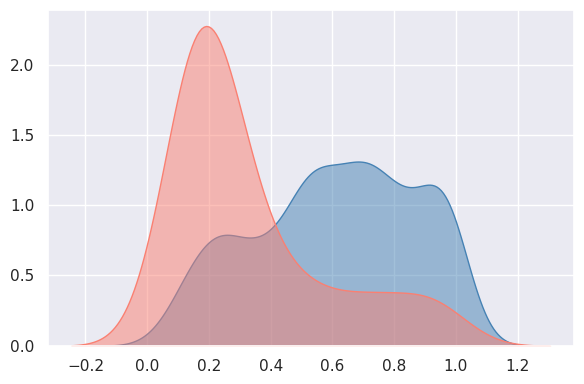

✅ 저장 완료: /data/rlawlsgurjh/work/gitlab/CUE/chembl/figure/chembl_vs_davis/PI_kdeplot.png
✅ 저장 완료: /data/rlawlsgurjh/work/gitlab/CUE/chembl/figure/chembl_vs_davis/Ssel_histplot.png


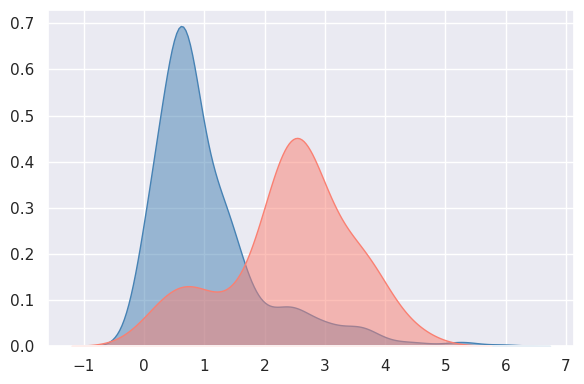

✅ 저장 완료: /data/rlawlsgurjh/work/gitlab/CUE/chembl/figure/chembl_vs_davis/Ssel_kdeplot.png
✅ 저장 완료: /data/rlawlsgurjh/work/gitlab/CUE/chembl/figure/chembl_vs_davis/WS(alpha=2)_histplot.png


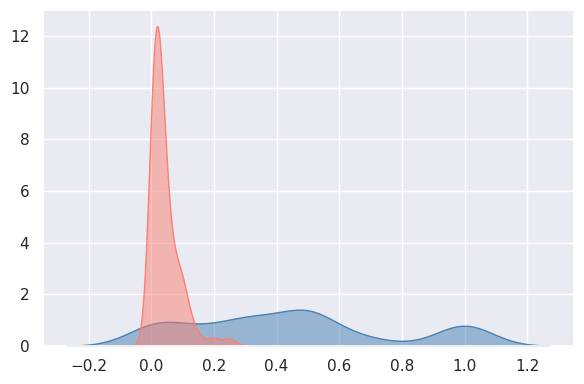

✅ 저장 완료: /data/rlawlsgurjh/work/gitlab/CUE/chembl/figure/chembl_vs_davis/WS(alpha=2)_kdeplot.png
✅ 저장 완료: /data/rlawlsgurjh/work/gitlab/CUE/chembl/figure/chembl_vs_davis/RS(k=2)_histplot.png


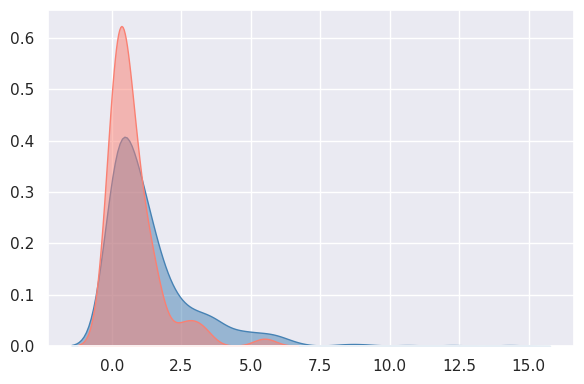

✅ 저장 완료: /data/rlawlsgurjh/work/gitlab/CUE/chembl/figure/chembl_vs_davis/RS(k=2)_kdeplot.png


In [21]:
for metric in target_metrics:
    plot_overlay_histplot(df_chembl, df_davis, metric, save_dir)
    plot_overlay_kdeplot(df_chembl, df_davis, metric, save_dir)